# ML-02 — Research Question and Provisional Lane

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YosraHilmi/Fly-Rank-Internship/blob/main/work/notebooks/w01_research_question.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. CTR / Engagement Opportunity Scoring
I chose the CTR / Engagement Opportunity Scoring lane because search rankings alone do not guarantee traffic. High impressions mean high visibility, but CTR determines whether users actually click. My focus is on identifying high-impression pages with low CTR, allowing us to increase traffic simply by getting more clicks from existing impressions, Instead of investing in costly, slow efforts to raise rankings or rewrite content from scratch, my focus is on pages that already earn high visibility but under-capture clicks. For these, the content team can test lower-cost changes to how the page appears in search results (title, meta description, snippet appeal) to try to turn existing impressions into more clicks.


---



## 2. The question: decision, action, cost of a wrong call

My work focuses on identifying pages with high visibility but low CTR and helping prioritize Which high-impression, low-CTR pages should be optimized first?.
It will benefit the SEO, marketing, and content teams by helping them decide which pages should be optimized first.
A wrong recommendation would waste the team's time and effort while missing opportunities to increase traffic and potential business value.


---



## 3. Quick look at the data


the first thing that i noticed There is almost no linear correlation between impressions and CTR (r = -0.019), suggesting that impression volume alone does not explain click-through rate.



In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/YosraHilmi/Fly-Rank-Internship/main/data/raw/content_refresh_anonymized.csv"
df = pd.read_csv(url)

df["impressions_90d"].corr(df["ctr"])

np.float64(-0.01894973657977031)



---



# Data Distribution & Correlation Audit:
After delving deeper into the data, I discovered that Initial evaluation using Pearson correlation suggested no relationship between impressions and CTR ($r = -0.0189$). However, distribution analysis revealed extreme right-skewness in both impressions_90d (skew = 11.38) and ctr (skew = 17.44), where means significantly dwarf medians.Switching to the outlier-robust Spearman rank correlation revealed a strong positive monotonic association ($r_s = 0.5398$). This proves that ranking metrics must be evaluated using non-parametric statistics or log-transformed values. Furthermore, extreme CTR max values ($100.0$) indicate low-impression noise that requires filtering before opportunity scoring.

=== 1. Skewness Values ===
Impressions Skewness: 11.38
CTR Skewness        : 17.44
-----------------------------------
=== 2. Mean vs Median Comparison ===
                        Mean  Median       Max
impressions_90d  5200.366300  731.00  517715.0
ctr                 0.510733    0.07     100.0
-----------------------------------
=== 3. Correlation Comparison ===
Pearson Correlation (Linear)   : -0.0189
Spearman Correlation (Monotonic): 0.5398


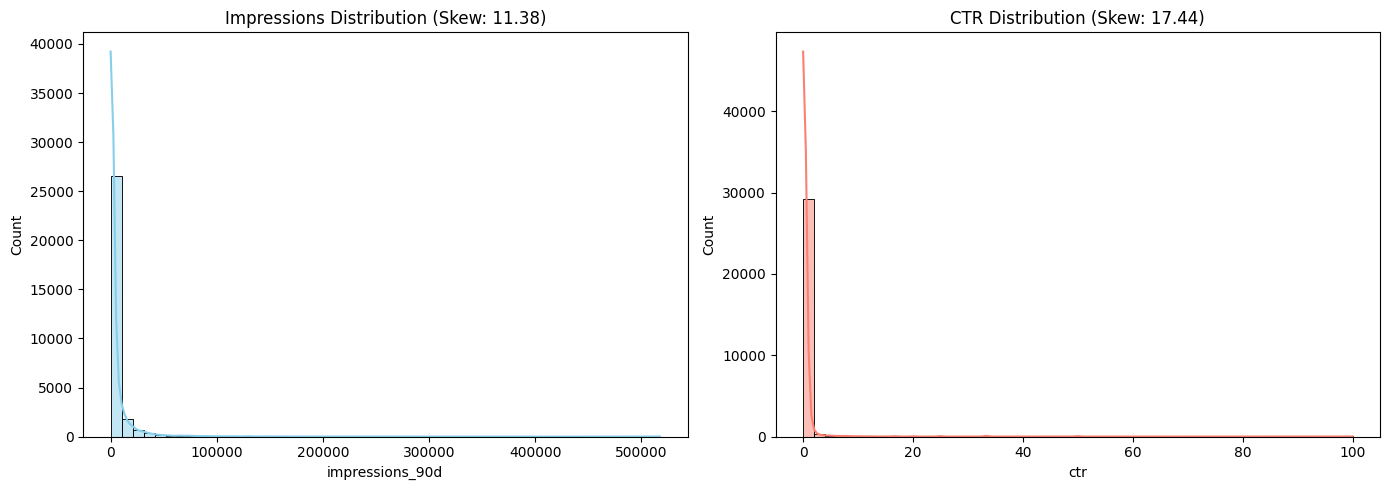

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate statistical skewness coefficient
skew_impressions = df['impressions_90d'].skew()
skew_ctr = df['ctr'].skew()

print("=== 1. Skewness Values ===")
print(f"Impressions Skewness: {skew_impressions:.2f}")
print(f"CTR Skewness        : {skew_ctr:.2f}")
print("-" * 35)

# 2. Compare Mean vs Median to prove influence of extreme outliers
stats_summary = pd.DataFrame({
    'Mean': [df['impressions_90d'].mean(), df['ctr'].mean()],
    'Median': [df['impressions_90d'].median(), df['ctr'].median()],
    'Max': [df['impressions_90d'].max(), df['ctr'].max()]
}, index=['impressions_90d', 'ctr'])

print("=== 2. Mean vs Median Comparison ===")
print(stats_summary)
print("-" * 35)

# 3. Calculate outlier-robust Spearman correlation and compare with Pearson
pearson_corr = df['impressions_90d'].corr(df['ctr'], method='pearson')
spearman_corr = df['impressions_90d'].corr(df['ctr'], method='spearman')

print("=== 3. Correlation Comparison ===")
print(f"Pearson Correlation (Linear)   : {pearson_corr:.4f}")
print(f"Spearman Correlation (Monotonic): {spearman_corr:.4f}")

# 4. Plot histograms to visualize distribution skewness
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['impressions_90d'], bins=50, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title(f"Impressions Distribution (Skew: {skew_impressions:.2f})")

sns.histplot(df['ctr'], bins=50, kde=True, ax=axes[1], color='salmon')
axes[1].set_title(f"CTR Distribution (Skew: {skew_ctr:.2f})")

plt.tight_layout()
plt.show()



---



The scatter plot shows that many pages receive high numbers of impressions while still having low CTR. These pages represent potential opportunities for optimization because increasing their CTR could generate more traffic without improving their search ranking.

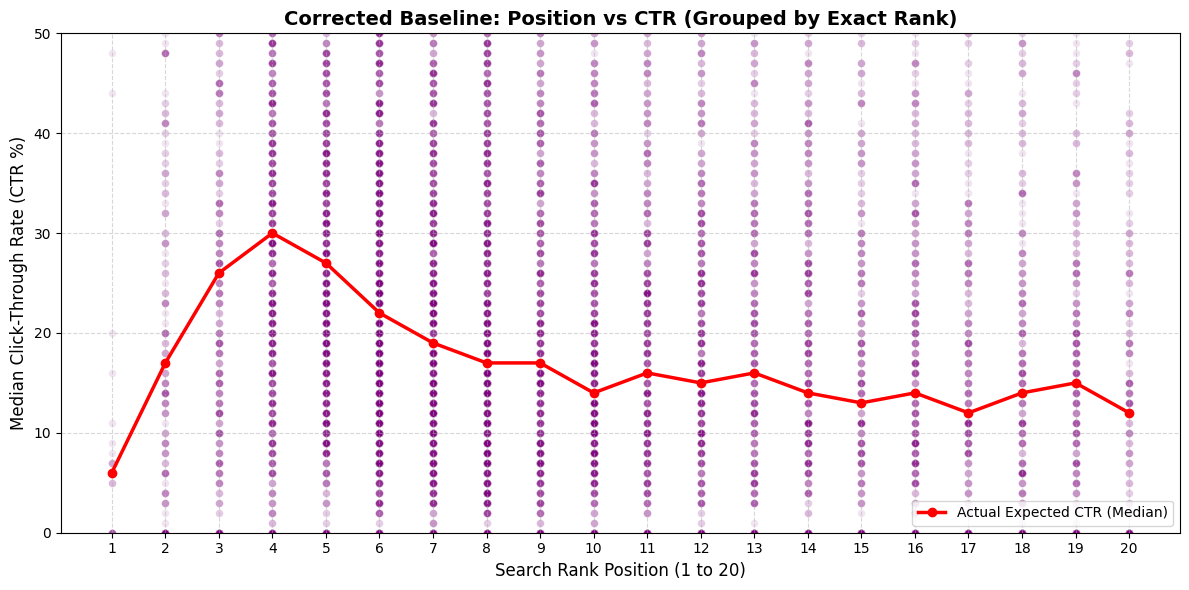

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Strict filtering and integer binning for position
plot_df = df[
    (df['impressions_90d'] >= 100) &
    (df['avg_position'] >= 1) &
    (df['avg_position'] <= 20) &
    (df['ctr'] <= 1.0)
].copy()

# Scale CTR correctly to Percentage
plot_df['ctr_pct'] = plot_df['ctr'] * 100

# Bin explicitly into integer ranks (1, 2, 3... 20)
plot_df['rank'] = plot_df['avg_position'].round().astype(int)

# 2. Calculate true median CTR per exact rank
rank_stats = plot_df.groupby('rank')['ctr_pct'].median().reset_index()

# 3. Clean Visualizing using sns.lineplot with confidence interval or clear markers
plt.figure(figsize=(12, 6))

# Plot line representing exact median CTR per rank
plt.plot(
    rank_stats['rank'],
    rank_stats['ctr_pct'],
    color='red',
    marker='o',
    linewidth=2.5,
    label='Actual Expected CTR (Median)'
)

# Optional scatter overlay with low opacity
sns.scatterplot(
    data=plot_df,
    x='rank',
    y='ctr_pct',
    alpha=0.1,
    color='purple',
    s=30
)

plt.title('Corrected Baseline: Position vs CTR (Grouped by Exact Rank)', fontsize=14, fontweight='bold')
plt.xlabel('Search Rank Position (1 to 20)', fontsize=12)
plt.ylabel('Median Click-Through Rate (CTR %)', fontsize=12)

plt.xticks(range(1, 21))
plt.ylim(0, 50)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()



---



These pages already receive substantial visibility but attract relatively few clicks. This suggests that they may represent valuable opportunities for CTR optimization without requiring improvements in search ranking.





In [ ]:
# Calculate the median values for 'impressions_90d' and 'ctr'
median_impressions = df['impressions_90d'].median()
median_ctr = df['ctr'].median()

print(f"Median 'impressions_90d': {median_impressions:.2f}")
print(f"Median 'ctr': {median_ctr:.4f}")

# Identify pages with impressions_90d greater than the median and ctr lower than the median
opportunity_pages = df[
    (df['impressions_90d'] > median_impressions) &
    (df['ctr'] < median_ctr)
]

# Count the number of such pages
count_opportunity_pages = len(opportunity_pages)

# Calculate the percentage of such pages relative to all pages
percentage_opportunity_pages = (count_opportunity_pages / len(df)) * 100

print(f"\nNumber of pages with high impressions and low CTR: {count_opportunity_pages}")
print(f"Percentage of all pages: {percentage_opportunity_pages:.2f}%")

Median 'impressions_90d': 731.00
Median 'ctr': 0.0700

Number of pages with high impressions and low CTR: 3309
Percentage of all pages: 11.03%




---



## 4. Careful words: what I can and can't claim

in the next weeks, i hope my work will be eable to predict the best pages opportunities to enhance thier trafic and to rate them by score to help decision support in the company and saving time and effort, this work will never predect how google algorithm work or proof an undeniable fact, The work will involve reading and analyzing the data, and uncovering patterns that will assist us in our mission.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.